<a href="https://colab.research.google.com/github/Killeryoung/ML/blob/main/%D0%9B%D0%A06_%D0%93%D1%83%D1%80%D0%BA%D0%BE_%D0%A4%D0%86%D0%A2_3_10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Лабораторна робота — Класифікація. Запобігання перенавчанню (виконано)**

**Класифікація. Запобігання перенавчанню**

Датасет: https://www.kaggle.com/datasets/iammustafatz/diabetes-prediction-dataset?select=diabetes_prediction_dataset.csv

Виконуйте завдання послідовно. **До аналізу кореляцій і викидів спочатку зробіть train/test split.** В усіх завданнях для дослідження кореляцій, меж IQR і асиметрії використовуйте **тільки train**. Не видаляйте викиди автоматично, не балансуйте test. Заповніть код у клітинках `TODO`, додайте короткі висновки та результати.

Потрібно навчити LogisticRegression, RidgeClassifier, SGDClassifier, SVC, вивести звіти та матриці плутанини, підібрати параметри методом HalvingGridSearchCV (`cv=3`) і показати 10 тестових прогнозів.

*Виберіть лише один зі способів завантаження даних нижче.*

In [1]:
from google.colab import files
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

**Спосіб 1.** Завантажити CSV із комп’ютера (Google Colab)

In [4]:
# Завантаження файлу
uploaded = files.upload()

Saving diabetes_prediction_dataset.csv to diabetes_prediction_dataset.csv


In [5]:
df = pd.read_csv('diabetes_prediction_dataset.csv')
df

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0
...,...,...,...,...,...,...,...,...,...
99995,Female,80.0,0,0,No Info,27.32,6.2,90,0
99996,Female,2.0,0,0,No Info,17.37,6.5,100,0
99997,Male,66.0,0,0,former,27.83,5.7,155,0
99998,Female,24.0,0,0,never,35.42,4.0,100,0


**Спосіб 2.** Завантажити датасет з Kaggle (Google Colab)

In [2]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download('iammustafatz/diabetes-prediction-dataset')

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'diabetes-prediction-dataset' dataset.
Path to dataset files: /kaggle/input/diabetes-prediction-dataset


In [3]:
df = pd.read_csv(os.path.join(path, "diabetes_prediction_dataset.csv"))
df

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0
...,...,...,...,...,...,...,...,...,...
99995,Female,80.0,0,0,No Info,27.32,6.2,90,0
99996,Female,2.0,0,0,No Info,17.37,6.5,100,0
99997,Male,66.0,0,0,former,27.83,5.7,155,0
99998,Female,24.0,0,0,never,35.42,4.0,100,0


Вивести інформацію про датасет

In [6]:
# TODO: виведіть df.info() і коротко прокоментуйте типи даних.
df.info()
print('Числові ознаки мають тип int/float, категоріальні — object.')

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 9 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   gender               100000 non-null  object 
 1   age                  100000 non-null  float64
 2   hypertension         100000 non-null  int64  
 3   heart_disease        100000 non-null  int64  
 4   smoking_history      100000 non-null  object 
 5   bmi                  100000 non-null  float64
 6   HbA1c_level          100000 non-null  float64
 7   blood_glucose_level  100000 non-null  int64  
 8   diabetes             100000 non-null  int64  
dtypes: float64(3), int64(4), object(2)
memory usage: 6.9+ MB
Числові ознаки мають тип int/float, категоріальні — object.


Провести дослідження категоріальних ознак

In [7]:
# TODO: підрахуйте частоти категорій у gender.
print(df['gender'].value_counts())

gender
Female    58552
Male      41430
Other        18
Name: count, dtype: int64


In [8]:
# TODO: підрахуйте частоти категорій у smoking_history.
print(df['smoking_history'].value_counts())

smoking_history
No Info        35816
never          35095
former          9352
current         9286
not current     6447
ever            4004
Name: count, dtype: int64


In [9]:
# TODO: df
display(df.head())

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0


Вивести типи даних

In [10]:
# TODO: df.dtypes
print(df.dtypes)

gender                  object
age                    float64
hypertension             int64
heart_disease            int64
smoking_history         object
bmi                    float64
HbA1c_level            float64
blood_glucose_level      int64
diabetes                 int64
dtype: object


Дослідити цільову змінну: перевірити баланс класів

In [11]:
# TODO: df['diabetes'].value_counts()
print(df['diabetes'].value_counts())
print(df['diabetes'].value_counts(normalize=True).round(3))

diabetes
0    91500
1     8500
Name: count, dtype: int64
diabetes
0    0.915
1    0.085
Name: proportion, dtype: float64


Висновок: визначте за результатом, чи є дисбаланс класів.

Перевірити наявність пропущених даних


In [12]:
# TODO: df.isnull().sum()
print(df.isnull().sum())

gender                 0
age                    0
hypertension           0
heart_disease          0
smoking_history        0
bmi                    0
HbA1c_level            0
blood_glucose_level    0
diabetes               0
dtype: int64


Наявність дублікатів


In [13]:
# TODO: df.duplicated().sum()
print('Дублікатів:', df.duplicated().sum())

Дублікатів: 3854


Видалити дублікати

In [14]:
# TODO: df.drop_duplicates(inplace=True)
df.drop_duplicates(inplace=True)
print('Після видалення дублікатів:', df.shape)

Після видалення дублікатів: (96146, 9)


In [15]:
# TODO: df
display(df.head())

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0


Ще раз перевірити баланс цільової змінної

In [16]:
# TODO: df['diabetes'].value_counts()
print(df['diabetes'].value_counts())
print(df['diabetes'].value_counts(normalize=True).round(3))

diabetes
0    87664
1     8482
Name: count, dtype: int64
diabetes
0    0.912
1    0.088
Name: proportion, dtype: float64


Побудувати гістограму для цільової змінної


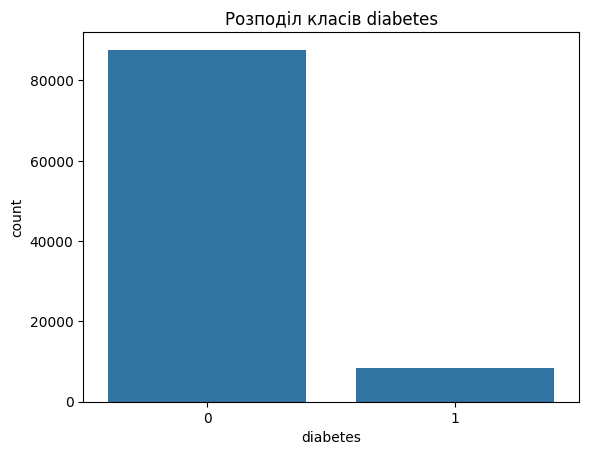

In [17]:
# TODO: sns.countplot(x='diabetes', data=df, color='tab:blue')
sns.countplot(x='diabetes', data=df, color='tab:blue')
plt.title('Розподіл класів diabetes')
plt.show()

Переглянути описові статистики **навчальної вибірки**

In [18]:
from sklearn.linear_model import LogisticRegression, RidgeClassifier, SGDClassifier
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
from imblearn.over_sampling import SMOTE

In [19]:
# TODO: створіть X та y, де y — стовпець diabetes.
# TODO: поділіть X та y на train і test у пропорції 80/20.
# Використайте random_state=42 та stratify=y.
X = df.drop(columns='diabetes')
y = df['diabetes']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print('Train:', X_train.shape, 'Test:', X_test.shape)

Train: (76916, 8) Test: (19230, 8)


Закодувати категоріальні ознаки **після поділу**. Створюємо стовпці за категоріями з train; у test залишаємо точно такий самий набір стовпців.

In [20]:
# TODO: використайте pd.get_dummies для gender та smoking_history.
# TODO: закодуйте X_train та X_test.
# TODO: вирівняйте стовпці X_test за X_train через reindex(..., fill_value=0).
categorical_cols = ['gender', 'smoking_history']
X_train = pd.get_dummies(X_train, columns=categorical_cols, dtype=int)
X_test = pd.get_dummies(X_test, columns=categorical_cols, dtype=int)
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)
print('Кількість ознак:', X_train.shape[1])

Кількість ознак: 15


In [21]:
# TODO: виведіть статистики опису X_train.
display(X_train.describe().T)

,count,mean,std,min,25%,50%,75%,max
age,76916.0,41.760982,22.467762,0.08,24.00,43.00,59.00,80.00
hypertension,76916.0,0.078007,0.268185,0.00,0.00,0.00,0.00,1.00
heart_disease,76916.0,0.040876,0.198004,0.00,0.00,0.00,0.00,1.00
bmi,76916.0,27.313739,6.757207,10.01,23.39,27.32,29.85,95.22
HbA1c_level,76916.0,5.530527,1.072421,3.50,4.80,5.80,6.20,9.00
blood_glucose_level,76916.0,138.114281,40.896909,80.00,100.00,140.00,159.00,300.00
gender_Female,76916.0,0.582675,0.493121,0.00,0.00,1.00,1.00,1.00
gender_Male,76916.0,0.417143,0.493090,0.00,0.00,0.00,1.00,1.00
gender_Other,76916.0,0.000182,0.013490,0.00,0.00,0.00,0.00,1.00
smoking_history_No Info,76916.0,0.342022,0.474390,0.00,0.00,0.00,1.00,1.00


Перевірити кореляцію ознак із цільовою змінною **лише на train**

In [22]:
# TODO: обчисліть кореляцію X_train із y_train (не використовуйте df або y_test).
target_corr = X_train.assign(diabetes=y_train).corr(numeric_only=True)['diabetes'].drop('diabetes').sort_values(key=abs, ascending=False)
print(target_corr)

blood_glucose_level            0.423011
HbA1c_level                    0.405321
age                            0.266649
bmi                            0.213456
hypertension                   0.199069
heart_disease                  0.174470
smoking_history_No Info       -0.113053
smoking_history_former         0.096162
gender_Male                    0.040650
gender_Female                 -0.040533
smoking_history_never          0.025725
smoking_history_ever           0.020899
smoking_history_not current    0.018841
smoking_history_current        0.013508
gender_Other                  -0.004197
Name: diabetes, dtype: float64


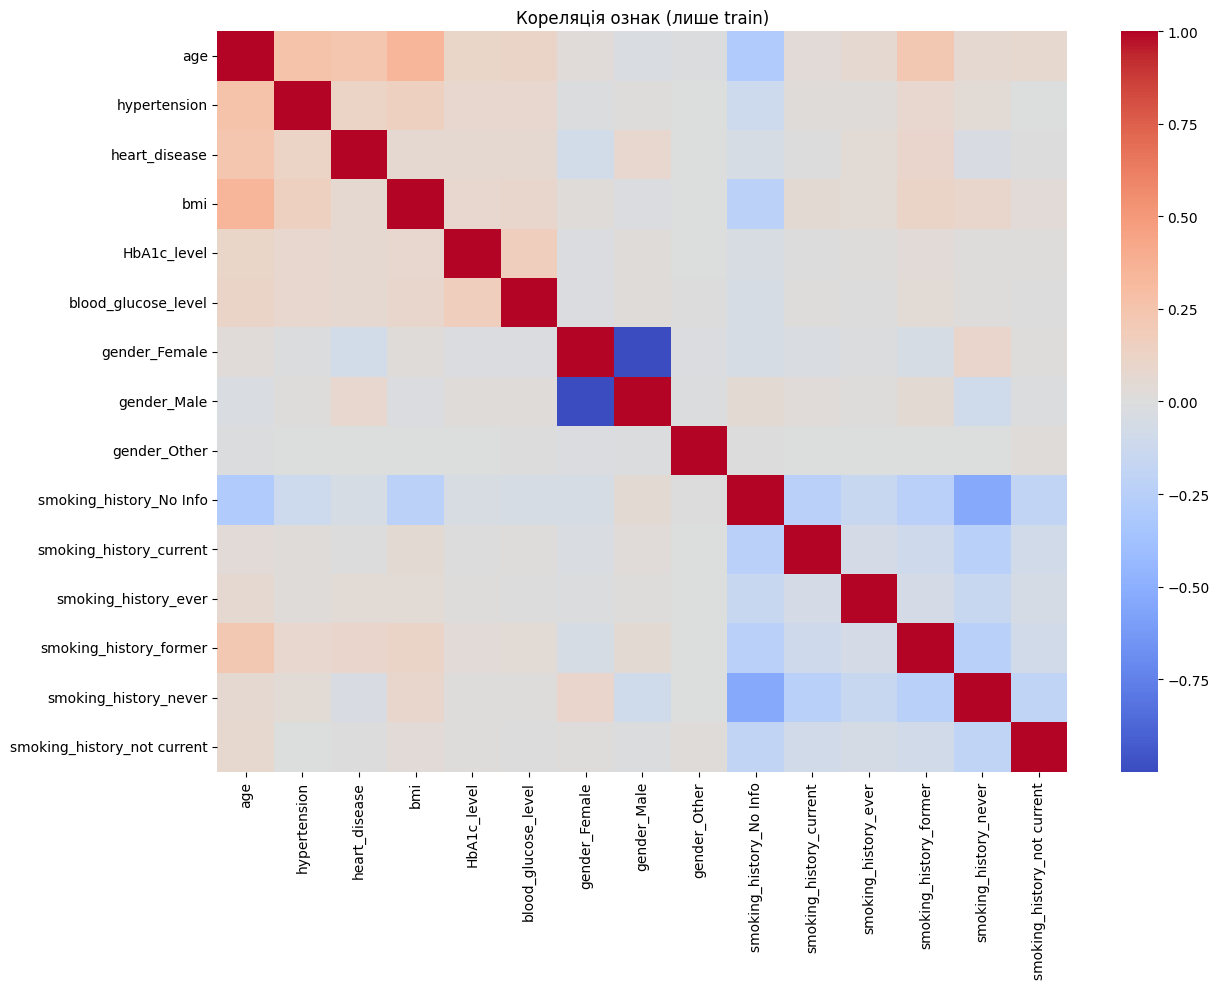

In [23]:
# TODO: обчисліть матрицю кореляції ознак X_train.
# TODO: побудуйте теплову карту (sns.heatmap).
plt.figure(figsize=(13, 10))
sns.heatmap(X_train.corr(numeric_only=True), cmap='coolwarm', center=0, annot=False)
plt.title('Кореляція ознак (лише train)')
plt.tight_layout()
plt.show()

**Висновок:** які ознаки сильно корелюють між собою або з цільовою змінною? Чи потрібно видаляти ознаки? Обґрунтуйте відповідь. **Тестові дані для такого рішення не використовуємо.**

Кореляції обчислено виключно на навчальній вибірці. Найсильніші зв’язки з цільовою змінною можна побачити у таблиці вище; взаємну кореляцію - на тепловій карті. Ознаки не видаляємо автоматично: для цього потрібне обґрунтування та перевірка на CV.


Перевірити викиди **лише на навчальній вибірці**

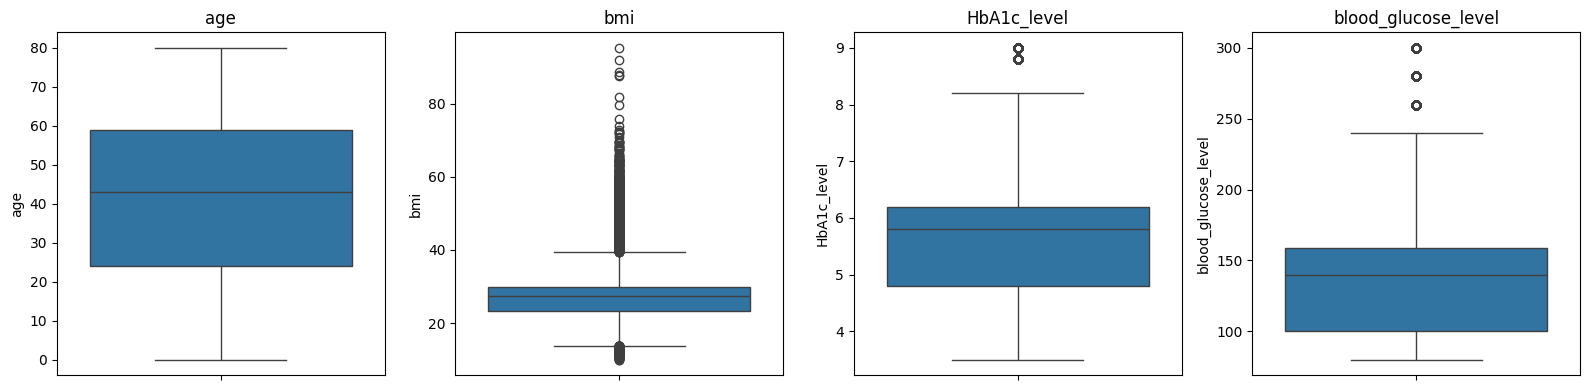

In [24]:
# TODO: задайте continuous_cols для age, bmi, HbA1c_level, blood_glucose_level.
# TODO: побудуйте boxplot за X_train[continuous_cols], НЕ за df.
continuous_cols = ['age', 'bmi', 'HbA1c_level', 'blood_glucose_level']
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, col in zip(axes, continuous_cols):
    sns.boxplot(y=X_train[col], ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

**Висновок:** викиди перевіряємо, але в цій лабораторній роботі автоматично **не видаляємо**. Екстремальні значення глюкози та HbA1c можуть бути клінічно важливими.

**Необов’язковий приклад.** Якщо потрібно видалити викиди методом IQR, межі обчислюємо **тільки на train**, видаляємо відповідні рядки з `X_train` і `y_train`, а `X_test` та `y_test` не змінюємо. У цій роботі приклад не запускаємо.

In [25]:
# НЕОБОВ'ЯЗКОВО: опишіть, як обчислити IQR для bmi тільки на X_train.
# Якщо вирішите вилучати рядки, синхронно оновіть X_train та y_train.
# Тестові дані не змінюйте. У цій роботі викиди не видаляємо.
q1, q3 = X_train['bmi'].quantile([0.25, 0.75])
iqr = q3 - q1
print('Межі IQR для bmi:', q1 - 1.5*iqr, q3 + 1.5*iqr)

Межі IQR для bmi: 13.7 39.540000000000006


Перевірити асиметрію розподілів ознак **на train**

In [26]:
# TODO: знайдіть асиметрію розподілів X_train[continuous_cols].
print(X_train[continuous_cols].skew().round(3))

age                   -0.061
bmi                    1.005
HbA1c_level           -0.056
blood_glucose_level    0.831
dtype: float64


In [27]:
# TODO: перевірте пропуски окремо в X_train та X_test.
print('Пропуски train:', X_train.isnull().sum().sum())
print('Пропуски test:', X_test.isnull().sum().sum())

Пропуски train: 0
Пропуски test: 0


**Проміжний висновок:** опишіть баланс класів, кореляції та викиди на train. Тестову вибірку залишаємо незмінною.

Розподіл класів до й після видалення дублікатів наведено вище. Дані мають дисбаланс на користь класу 0. Викиди проаналізовано на train, але не видалено, оскільки вони можуть містити корисні клінічні сигнали. Test не змінюємо.


Масштабуємо ознаки: `fit_transform` лише для train, `transform` — для test.

In [28]:
# TODO: створіть StandardScaler.
# TODO: виконайте fit_transform на X_train і transform на X_test.
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

Балансуємо лише навчальну вибірку за допомогою SMOTE

In [29]:
# TODO: збалансуйте тільки масштабовану навчальну вибірку методом SMOTE.
# TODO: порівняйте кількості класів до та після балансування.
smote = SMOTE(random_state=42)
X_train_balanced, y_train_balanced = smote.fit_resample(X_train_scaled, y_train)
print('До SMOTE:', y_train.value_counts().to_dict())
print('Після SMOTE:', pd.Series(y_train_balanced).value_counts().to_dict())

До SMOTE: {0: 70130, 1: 6786}
Після SMOTE: {0: 70130, 1: 70130}


Оголошуємо моделі

In [30]:
# TODO: створіть словник models для чотирьох моделей:
# LogisticRegression, RidgeClassifier, SGDClassifier, SVC.
# Для відтворюваності вкажіть random_state=42, де це передбачено.
models = {
    'LogisticRegression': LogisticRegression(max_iter=1500, random_state=42),
    'RidgeClassifier': RidgeClassifier(random_state=42),
    'SGDClassifier': SGDClassifier(random_state=42),
    'SVC': SVC(random_state=42, cache_size=500)
}

Навчити моделі, вивести матриці плутанини, класифікаційний звіт



=== LogisticRegression ===
              precision    recall  f1-score   support

           0       0.99      0.89      0.93     17534
           1       0.43      0.88      0.57      1696

    accuracy                           0.88     19230
   macro avg       0.71      0.88      0.75     19230
weighted avg       0.94      0.88      0.90     19230



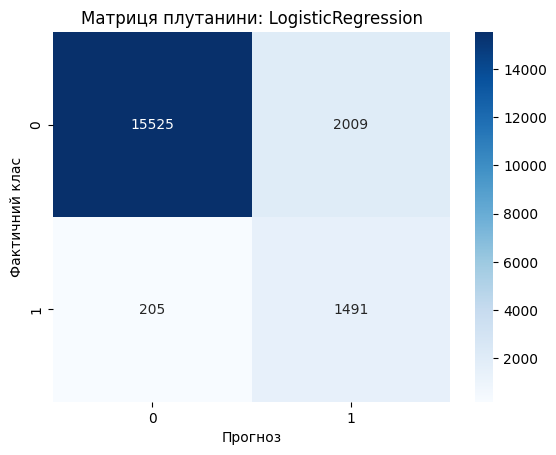


=== RidgeClassifier ===
              precision    recall  f1-score   support

           0       0.99      0.89      0.94     17534
           1       0.43      0.88      0.58      1696

    accuracy                           0.89     19230
   macro avg       0.71      0.88      0.76     19230
weighted avg       0.94      0.89      0.90     19230



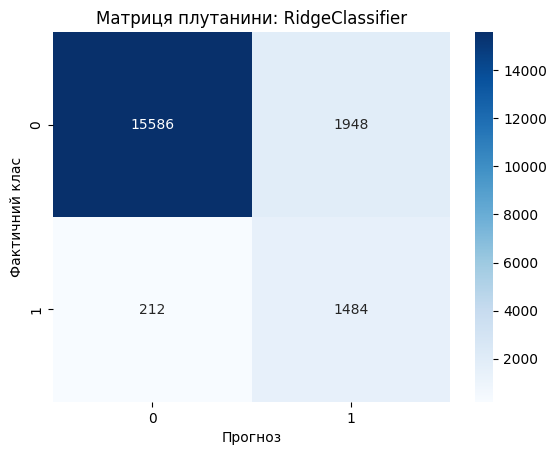


=== SGDClassifier ===
              precision    recall  f1-score   support

           0       0.99      0.86      0.92     17534
           1       0.38      0.91      0.53      1696

    accuracy                           0.86     19230
   macro avg       0.68      0.88      0.73     19230
weighted avg       0.94      0.86      0.88     19230



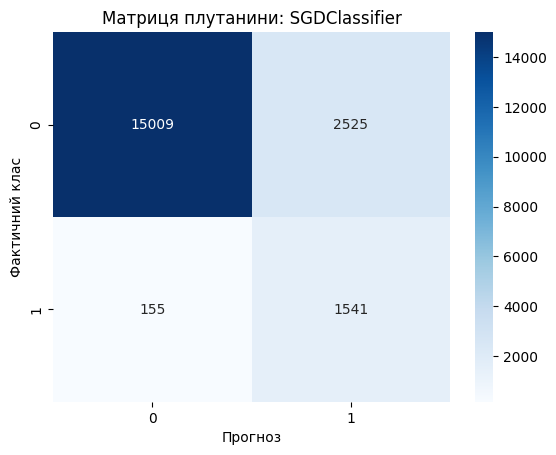


=== SVC ===
              precision    recall  f1-score   support

           0       0.99      0.88      0.93     17534
           1       0.43      0.91      0.58      1696

    accuracy                           0.88     19230
   macro avg       0.71      0.89      0.76     19230
weighted avg       0.94      0.88      0.90     19230



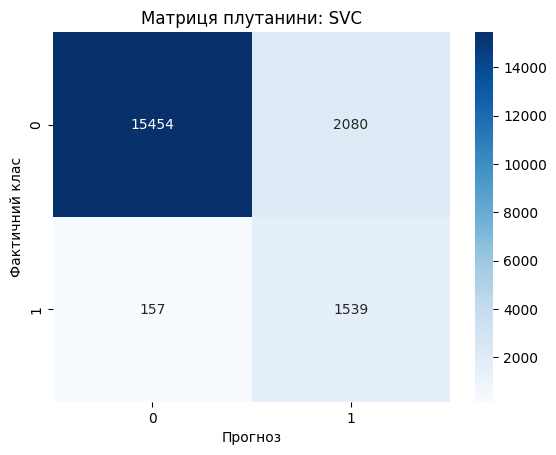

In [31]:
# TODO: навчіть кожну модель на збалансованій навчальній вибірці.
# TODO: зробіть прогноз на масштабованій X_test.
# TODO: виведіть classification_report та confusion_matrix (теплова карта).
baseline_results = {}
for name, model in models.items():
    print('\n===', name, '===')
    model.fit(X_train_balanced, y_train_balanced)
    pred = model.predict(X_test_scaled)
    baseline_results[name] = classification_report(y_test, pred, output_dict=True, zero_division=0)
    print(classification_report(y_test, pred, zero_division=0))
    sns.heatmap(confusion_matrix(y_test, pred), annot=True, fmt='d', cmap='Blues')
    plt.title(f'Матриця плутанини: {name}')
    plt.xlabel('Прогноз'); plt.ylabel('Фактичний клас')
    plt.show()

Оптимізувати гіперпараметри


In [32]:
# TODO: задайте словник param_grids для кожної моделі.
# Приклади: C та solver; alpha; loss та penalty; C та kernel.
param_grids = {
    'LogisticRegression': {'model__C': [0.1, 1, 10], 'model__solver': ['lbfgs']},
    'RidgeClassifier': {'model__alpha': [0.1, 1, 10]},
    'SGDClassifier': {'model__loss': ['hinge', 'log_loss'], 'model__penalty': ['l2', 'l1']},
    'SVC': {'model__C': [0.1, 1, 10], 'model__kernel': ['linear', 'rbf']}
}

Підбираємо параметри методом **HalvingGridSearchCV** із `cv=3`, `scoring="f1"`. Масштабування та SMOTE виконуються в кожному навчальному згині, щоб не було витоку даних. На малих порціях для пошуку задаємо достатній мінімальний розмір навчальних даних.

In [33]:
# Для HalvingGridSearchCV потрібен цей імпорт перед основним імпортом.
from sklearn.experimental import enable_halving_search_cv
from sklearn.model_selection import HalvingGridSearchCV
from imblearn.pipeline import Pipeline

In [34]:
# TODO: створіть best_models і best_scores.
# TODO: для кожної моделі визначте Pipeline: StandardScaler -> SMOTE -> модель.
# TODO: запустіть HalvingGridSearchCV із cv=3, scoring='f1', min_resources=300.
# TODO: шукайте параметри ТІЛЬКИ на X_train, y_train.
# TODO: виведіть оптимальні параметри та класифікаційний звіт.
best_models = {}
best_scores = {}
for name, model in models.items():
    print('\nПідбір параметрів:', name)
    pipeline = Pipeline([('scaler', StandardScaler()), ('smote', SMOTE(random_state=42)), ('model', model)])
    search = HalvingGridSearchCV(pipeline, param_grids[name], cv=3, scoring='f1', min_resources=300, factor=3, n_jobs=-1, error_score='raise')
    search.fit(X_train, y_train)
    best_models[name] = search.best_estimator_
    best_scores[name] = search.best_score_
    print('Найкращі параметри:', search.best_params_)
    print('Середній F1 (CV):', round(search.best_score_, 4))
    print(classification_report(y_test, search.predict(X_test), zero_division=0))


Підбір параметрів: LogisticRegression
Найкращі параметри: {'model__C': 10, 'model__solver': 'lbfgs'}
Середній F1 (CV): 0.5242
              precision    recall  f1-score   support

           0       0.99      0.89      0.93     17534
           1       0.43      0.88      0.57      1696

    accuracy                           0.88     19230
   macro avg       0.71      0.88      0.75     19230
weighted avg       0.94      0.88      0.90     19230


Підбір параметрів: RidgeClassifier
Найкращі параметри: {'model__alpha': 10}
Середній F1 (CV): 0.5636
              precision    recall  f1-score   support

           0       0.99      0.89      0.94     17534
           1       0.43      0.88      0.58      1696

    accuracy                           0.89     19230
   macro avg       0.71      0.88      0.76     19230
weighted avg       0.94      0.89      0.90     19230


Підбір параметрів: SGDClassifier
Найкращі параметри: {'model__loss': 'hinge', 'model__penalty': 'l1'}
Середній F1 (C

Вибрати найкращу модель за середнім F1 на кросвалідації (а не за тестовою вибіркою)

In [35]:
# TODO: виберіть найкращу модель за середнім F1 на кросвалідації.
# Збережіть її в змінну best_model і виведіть назву та F1.
best_name = max(best_scores, key=best_scores.get)
best_model = best_models[best_name]
print('Найкраща модель:', best_name)
print('F1 на кросвалідації:', round(best_scores[best_name], 4))

Найкраща модель: SVC
F1 на кросвалідації: 0.6483


In [36]:
# TODO: виберіть 10 випадкових індексів тестової вибірки (random_state=42).
# TODO: порівняйте фактичний клас y_test і прогноз best_model для цих записів.
# Виведіть таблицю: індекс, істинний клас, передбачений клас.
sample_idx = X_test.sample(n=10, random_state=42).index
comparison = pd.DataFrame({'індекс': sample_idx, 'істинний клас': y_test.loc[sample_idx].to_numpy(), 'передбачений клас': best_model.predict(X_test.loc[sample_idx])})
display(comparison)

,індекс,істинний клас,передбачений клас
0,36061,0,0
1,29824,0,0
2,29668,0,1
3,11816,0,0
4,99242,0,0
5,26718,0,0
6,53059,0,0
7,69294,0,0
8,8912,0,1
9,37072,0,0


**Підсумкові висновки (заповніть самостійно):**

1. Який дисбаланс класів спостерігався? Що показали кореляція та перевірка викидів **на train**?
2. Які моделі дали кращі `F1` і `recall` для класу `diabetes = 1`? Яка модель обрана за кросвалідацією?
3. Які оптимальні гіперпараметри отримано? Які помилки видно в матриці плутанини?
4. Навіщо відкладати тестові дані та виконувати масштабування й SMOTE тільки на train?


У наборі переважає клас `diabetes=0`, тому є дисбаланс. Кореляції та викиди досліджувалися тільки на train; значення HbA1c і глюкози можуть бути важливими для класифікації.

Порівняння F1 і recall для класу 1 наведено в `classification_report` для кожної моделі. Найкращу модель автоматично визначає клітинка вище за середнім F1 кросвалідації, а не за test.

Оптимальні гіперпараметри виводяться після `HalvingGridSearchCV`. У матрицях плутанини FP - хибні позитивні прогнози, FN - пропущені випадки діабету.

Відкладений test забезпечує чесну перевірку узагальнення. Масштабування й SMOTE всередині CV-пайплайна навчаються тільки на відповідних тренувальних згинах, щоб уникнути витоку даних.
